In [1]:
# Fit the EE Morse contribution while keeping previously trained CC and EC contributions fixed
import time
import os
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt


from pathlib import Path

DATA_DIR = Path("../data/training")

pairwise_dis_ce = [
    DATA_DIR / "edge_to_edge" / "PairDis_1_CC.npy",
    DATA_DIR / "face_to_face" / "PairDis_1_CC.npy",
]

pairwise_dis_ed_cen = [
    DATA_DIR / "edge_to_edge" / "PairDis_1_EC.npy",
    DATA_DIR / "face_to_face" / "PairDis_1_EC.npy",
]

pairwise_dis_cen_ed = [
    DATA_DIR / "edge_to_edge" / "PairDis_1_CE.npy",
    DATA_DIR / "face_to_face" / "PairDis_1_CE.npy",
]

pairwise_dis_ed = [
    DATA_DIR / "edge_to_edge" / "PairDis_1_EE.npy",
    DATA_DIR / "face_to_face" / "PairDis_1_EE.npy",
]

Actual_data = [
    DATA_DIR / "edge_to_edge" / "distance_edge_1_ext.out",
    DATA_DIR / "face_to_face" / "dspacing_PMF.out",
]




device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

def load_pairwise_distances(file_path):
    data = np.load(file_path, allow_pickle=True).item()  # Load as dictionary
    if not isinstance(data, dict):
        raise ValueError(f"Loaded data is not a dictionary: {type(data)} from {file_path}")


    sorted_keys = sorted(data.keys())
    d_spacing = torch.tensor(sorted_keys, dtype=torch.float32, device=device)
    distances = [torch.tensor(data[key], dtype=torch.float32, device=device) for key in sorted_keys]

    return d_spacing, distances

# Load actual energies and pairwise distances
processed_data = {}
actual_energies = {}

for i, file_path in enumerate(pairwise_dis_ce):
    dataset_key = f'dataset_{i+1}'
    processed_data[dataset_key] = {}

    # Load pairwise distances
    d_spacing_cc, dist_cc = load_pairwise_distances(file_path)
    processed_data[dataset_key]["d_spacing"] = d_spacing_cc
    processed_data[dataset_key]["center_center"] = dist_cc  # List of tensors
    

    print(f"✔ Loaded {file_path} - {len(dist_cc)} d-spacing values.")
    
for i, file_path in enumerate(pairwise_dis_ed_cen):
    dataset_key = f'dataset_{i+1}'
#     processed_data[dataset_key] = {}

    # Load pairwise distances
    d_spacing_ec, dist_ec = load_pairwise_distances(file_path)
    processed_data[dataset_key]["d_spacing"] = d_spacing_ec
    processed_data[dataset_key]["edge_center"] = dist_ec  # List of tensors
    

    print(f"✔ Loaded {file_path} - {len(dist_ec)} d-spacing values.")
    
    
for i, file_path in enumerate(pairwise_dis_cen_ed):
    dataset_key = f'dataset_{i+1}'

    # Load pairwise distances
    d_spacing_ce, dist_ce = load_pairwise_distances(file_path)
    processed_data[dataset_key]["d_spacing"] = d_spacing_ce
    processed_data[dataset_key]["center_edge"] = dist_ce  # List of tensors
    

    print(f"✔ Loaded {file_path} - {len(dist_ce)} d-spacing values.")
    
    
    
for i, file_path in enumerate(pairwise_dis_ed):
    dataset_key = f'dataset_{i+1}'

    # Load pairwise distances
    d_spacing_ee, dist_ee = load_pairwise_distances(file_path)
    processed_data[dataset_key]["d_spacing"] = d_spacing_ee
    processed_data[dataset_key]["edge_edge"] = dist_ee  # List of tensors
    

    print(f"✔ Loaded {file_path} - {len(dist_ee)} d-spacing values.")

# Load actual energy data
for i, file_path in enumerate(Actual_data):
    dataset_key = f'dataset_{i+1}'
    data = np.loadtxt(file_path, delimiter=' ')

    # Sort data by d-spacing
    sorted_indices = np.argsort(data[:, 0])
    data = data[sorted_indices]  # Apply sorting

    d_space = torch.tensor(data[:, 0], dtype=torch.float32, device=device)
    energy_values = torch.tensor(data[:, 1], dtype=torch.float32, device=device)

    # Store in dictionaries
    processed_data[dataset_key]["d_spacing_energy"] = d_space
    processed_data[dataset_key]["actual"] = energy_values
    actual_energies[dataset_key] = energy_values

    # Check if d-spacing values match between .npy and .out files
    if not torch.allclose(d_space, processed_data[dataset_key]["d_spacing"]):
        print(f"⚠ Warning: d-spacing mismatch between .npy and .out files for {dataset_key}")

    print(f"✔ Loaded {file_path} - {len(data)} rows sorted.")

for dkey in processed_data.keys():
    # For each d-spacing, concatenate edge_center and center_edge tensors
    processed_data[dkey]["mix"] = [
        torch.cat([ec, ce]) 
        for ec, ce in zip(
            processed_data[dkey]["edge_center"], 
            processed_data[dkey]["center_edge"]
        )
    ]
    
    
# Verify loaded data
for key in processed_data:
    print(f"\nDataset: {key}")
    print(f"  d_spacing (from .npy): {processed_data[key]['d_spacing'].shape}")
    print(f"  d_spacing (from .out): {processed_data[key]['d_spacing_energy'].shape}")
    print(f"  center_center distances: {len(processed_data[key]['center_center'])} arrays")
    print(f"  edge_center distances: {len(processed_data[key]['edge_center'])} arrays")
    print(f"  center_edge distances: {len(processed_data[key]['center_edge'])} arrays")
    print(f"  mix distances: {len(processed_data[key]['mix'])} arrays")
    
    print(f"  edge_edge distances: {len(processed_data[key]['edge_edge'])} arrays")
    
    
    print(f"  Actual energies: {processed_data[key]['actual'].shape}")

    # Print first 5 d-spacing values and corresponding distances/energies
    print("\nFirst 5 d-spacing values and corresponding data:")
    for i in range(5):
        print(f"  d-spacing: {processed_data[key]['d_spacing'][i].item()}")
        print(f"    Number of distances_cc: {len(processed_data[key]['center_center'][i])}")
        print(f"    Number of distances_ec: {len(processed_data[key]['edge_center'][i])}")
        print(f"    Number of distances_ec: {len(processed_data[key]['center_edge'][i])}")
        print(f"    Number of distances_mix: {len(processed_data[key]['mix'][i])}")
        
        print(f"    Number of distances_ee: {len(processed_data[key]['edge_edge'][i])}")
        
        print(f"    Energy: {processed_data[key]['actual'][i].item()}")


Using device: cpu
✔ Loaded /Volumes/Work/SecondProject/LastVersion/Prepration_2/Edge-to-Edge/1/PairDis_1_CC.npy - 80 d-spacing values.
✔ Loaded /Volumes/Work/SecondProject/LastVersion/Prepration_2/Face-to-Face/1/PairDis_1_CC.npy - 150 d-spacing values.
✔ Loaded /Volumes/Work/SecondProject/LastVersion/Prepration_2/Edge-to-Edge/1/PairDis_1_EC.npy - 80 d-spacing values.
✔ Loaded /Volumes/Work/SecondProject/LastVersion/Prepration_2/Face-to-Face/1/PairDis_1_EC.npy - 150 d-spacing values.
✔ Loaded /Volumes/Work/SecondProject/LastVersion/Prepration_2/Edge-to-Edge/1/PairDis_1_CE.npy - 80 d-spacing values.
✔ Loaded /Volumes/Work/SecondProject/LastVersion/Prepration_2/Face-to-Face/1/PairDis_1_CE.npy - 150 d-spacing values.
✔ Loaded /Volumes/Work/SecondProject/LastVersion/Prepration_2/Edge-to-Edge/1/PairDis_1_EE.npy - 80 d-spacing values.
✔ Loaded /Volumes/Work/SecondProject/LastVersion/Prepration_2/Face-to-Face/1/PairDis_1_EE.npy - 150 d-spacing values.
✔ Loaded /Volumes/Work/SecondProject/LastV

In [4]:
#Optimized CC from previous stages
morse_cc = torch.tensor([-200.3445,    0.8255,   -2.2312], device=device)
num_S = 38
S_points = torch.tensor([0.0000,  1.0417,  2.0833,  2.6000,  3.1250,  3.6000,  4.1667,  4.6000,
         5.2083,  6.2500,  6.6000,  7.2917,  7.6000,  8.3333,  8.4000,  9.3750,
         9.6000, 10.4000, 10.4167, 11.4583, 11.6000, 12.4000, 12.5000, 13.5417,
        13.6000, 14.5833, 14.6000, 15.6000, 15.6250, 16.6667, 17.7083, 18.7500,
        19.7917, 20.8333, 21.8750, 22.9167, 23.9583, 25.0000
], device=device)


l_cc = torch.tensor(0.7842, device=device)

coeffs_cc = torch.tensor([0.0000e+00,  0.0000e+00,  6.3404e-07,  1.8891e+00,  8.1625e+00,
         1.0581e-01, -2.4098e+00, -4.0319e-01,  7.9287e-01, -1.9698e-01,
        -6.0995e-02,  7.0925e-02, -4.9648e-02, -5.2572e-02,  4.9121e-02,
         5.2969e-02, -2.1126e-02,  2.1917e-02, -5.2105e-02,  3.6958e-02,
        -4.6758e-02,  5.6710e-02, -1.1014e-02, -3.1777e-03, -1.9909e-02,
         6.7422e-03,  1.3268e-02, -1.1562e-03, -6.4095e-03,  4.7646e-03,
        -3.3277e-03,  2.0708e-03, -1.1522e-03,  6.7129e-04, -4.4138e-04,
         3.0538e-04, -1.4848e-04,  3.1906e-05
], device=device)

morse_ec = torch.tensor([-60.6008,   0.8054,  -0.4834], device=device)

l_ec = torch.tensor(0.9172, device=device)
coeffs_ec = torch.tensor([1.0000e-02,  1.0000e-02,  2.7176e-01,  1.8848e+00,  2.6622e+00,
        -8.0390e-01,  2.4433e+00,  5.5400e-02, -3.3196e+00,  2.7279e+00,
         4.3200e-02, -1.8347e+00, -2.9200e-02,  1.0011e+00,  2.5900e-02,
        -4.3774e-01, -5.2200e-02,  3.0100e-02,  1.9532e-01, -1.3795e-01,
        -6.3000e-03, -1.1700e-02,  1.2568e-01, -1.1154e-01, -7.1000e-03,
         9.7802e-02,  0.0000e+00,  0.0000e+00, -7.8401e-02,  6.1313e-02,
        -4.4903e-02,  3.1545e-02, -2.1325e-02,  1.4045e-02, -8.1299e-03,
         3.8430e-03, -9.9988e-04, -2.5886e-04
], device=device)





def morse_potential(r, D_e, a, r_e):
    delta = a * (r - r_e)
    exp_term = torch.exp(-delta)
    return D_e * (1 - exp_term)**2 - D_e

def calculate_kernels(distances, S_points, l):
    l = torch.clamp(l, min=1e-3)  # Ensure l > 0

    # Compute squared differences for all pairs (distances, S_points)
    diff = (distances.unsqueeze(1) - S_points) ** 2 / (2 * (l ** 2))  # Ensure 3D shape

    # Compute Gaussian kernel
    kernel_values = torch.exp(-diff)

    # Compute cutoff value at r = 3l
    cutoff_value = torch.exp(-((3 * l) ** 2) / (2 * (l ** 2)))

    # Apply cutoff: subtract cutoff_value
    kernel_values = kernel_values.clone() - cutoff_value  

    # Apply masking for cutoff
    mask = torch.abs(distances.unsqueeze(1) - S_points) > 3 * l
    kernel_values = torch.where(mask, torch.tensor(0.0, device=l.device), kernel_values)

    return kernel_values  # Ensures (N, S) shape


def precompute_cc_contributions(dist, morse, S_points, l, coeffs):
    morse_list = []
    pred_list = []

    for dist_tensor in dist:
        # Morse potential energy
        morse_energy = morse_potential(dist_tensor, *morse).sum()
        morse_list.append(morse_energy)

        # GPR contribution
        K = calculate_kernels(dist_tensor, S_points, l)
        pred = torch.einsum('ns,s->n', K, coeffs).sum()
        pred_list.append(pred)

    # Convert lists to tensors
    morse_tensor = torch.stack(morse_list)
    pred_tensor = torch.stack(pred_list)

    return morse_tensor, pred_tensor

precomputed = {}
for dkey in processed_data:
    dist_cc = processed_data[dkey]["center_center"]
    dist_mix = processed_data[dkey]["mix"]
    
    
    morse_cc_tensor, pred_cc_tensor = precompute_cc_contributions(dist_cc, morse_cc, S_points, l_cc, coeffs_cc)
    morse_ec_tensor, pred_ec_tensor = precompute_cc_contributions(dist_mix, morse_ec, S_points, l_ec, coeffs_ec)
    
    precomputed[dkey] = {
        "morse_cc": morse_cc_tensor,
        "pred_cc": pred_cc_tensor,
        "morse_ec": morse_ec_tensor,
        "pred_ec": pred_ec_tensor,
        
    }
        
        


        



In [ ]:
# Fixed CC and EC parameters from previous training stages

class Morse_EE_Model(nn.Module):
    def __init__(self, num_S=38):
        super().__init__()
        
        # Initial EE Morse parameters
        self.morse_ee = nn.Parameter(torch.tensor([-47.95616, 3.3437212  , -0.42243564], device=device))
        
    def morse_potential(self, r, D_e, a, r_e):
        delta = a * (r - r_e)
        exp_term = torch.exp(-delta)
        return D_e * (1 - exp_term)**2 - D_e
        
    def forward(self, data):
        total_loss = 0.0
        metrics = {'per_dataset': {}}
        
        for dkey in data.keys():
            dist_ee = data[dkey]["edge_edge"]
            actual = data[dkey]["actual"]
            
            # Calculate Morse EE contributions
            morse_ee_list = []
            for dist_tensor in dist_ee:
                morse_ee = self.morse_potential(dist_tensor, *self.morse_ee)
                morse_ee_list.append(morse_ee.sum())
            
            morse_ee_tensor = torch.stack(morse_ee_list)
            
            # Get precomputed values for this dataset
            precomp = precomputed[dkey]
            predicted = (
                morse_ee_tensor + 
                precomp["morse_cc"] + 
                precomp["pred_cc"] + 
                precomp["morse_ec"] + 
                precomp["pred_ec"]
            )
            
            # Verify sizes
            assert predicted.size() == actual.size(), (
                f"Size mismatch in {dkey}: "
                f"predicted {predicted.size()}, actual {actual.size()}"
            )
            
            # Weighted MSE loss
            weights = 1 / (torch.abs(actual) + 1e-3)
            weights = torch.clamp(weights, min=1/200.0, max=1.0)
            mse_loss = torch.mean(weights * (predicted - actual)**2)
            
            # Store metrics
            metrics['per_dataset'][dkey] = {
                'mse_loss': mse_loss.item(),
                'pred_range': (predicted.min().item(), predicted.max().item()),
                'actual_range': (actual.min().item(), actual.max().item())
            }
            
            total_loss += mse_loss
        
        
        # Store metrics for debugging
        self.last_metrics = metrics
        return total_loss

# Adam optimizer
model = Morse_EE_Model().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=0.01) 

# Training loop
num_epochs = 5000  
loss_values = []

for epoch in range(1, num_epochs + 1):
    optimizer.zero_grad()
    loss = model(processed_data)
    loss.backward()
    
    # Gradient clipping
    torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    
    optimizer.step()
    
    loss_values.append(loss.item())
    print(f"Epoch {epoch}/{num_epochs}, Loss: {loss.item():.6f}")
    
    if epoch % 10 == 0:
        print(f"Current params: {model.morse_ee.detach().cpu().numpy()}")
        
        # Print per-dataset metrics
        for dkey, m in model.last_metrics['per_dataset'].items():
            print(f"{dkey} - Pred: {m['pred_range']}, Actual: {m['actual_range']}")

# Plotting
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(loss_values)
plt.title("Training Loss")
plt.xlabel("Epoch")

plt.subplot(1, 2, 2)
plt.bar(['D_e', 'a', 'r_e'], model.morse_ee.detach().cpu().numpy())
plt.title("Final Morse Parameters")
plt.tight_layout()
plt.show()

print("Final parameters:", model.morse_ee.detach().cpu().numpy())

dataset_1 predicted energy: tensor([ 3.1328e+01,  2.8508e+01,  2.7688e+01,  2.2946e+01,  1.7926e+01,
         1.7492e+01,  1.4220e+01,  1.2699e+01,  1.1455e+01,  7.9610e+00,
         6.6473e+00,  6.0075e+00,  5.0234e+00,  4.8585e+00,  4.2051e+00,
         3.9581e+00,  3.3203e+00,  2.6947e+00,  2.3402e+00,  2.1071e+00,
         1.3138e+00,  9.1329e-01,  7.6373e-01,  6.3351e-01,  6.3097e-01,
         6.1756e-01,  5.4724e-01,  4.8937e-01,  3.8100e-01,  3.2059e-01,
         1.3568e-01,  1.3142e-02, -5.6547e-02, -8.5912e-02, -1.0408e-01,
        -1.1882e-01, -9.4017e-02, -7.5418e-02, -4.3552e-02, -2.4956e-02,
        -2.1285e-02, -2.4049e-02, -2.9480e-02, -4.3780e-02, -5.2955e-02,
        -7.3350e-02, -9.4606e-02, -9.0076e-02, -3.7336e-03,  8.6488e-02,
         6.5719e-02, -2.3470e-02, -5.9787e-02,  1.0962e-02,  8.7538e-02,
         4.6980e-02, -3.9328e-02, -4.7174e-02,  8.0591e-03,  5.2400e-02,
         2.8550e-02, -1.8994e-02, -3.0302e-02, -2.6960e-03,  2.2289e-02,
         1.5356e-02, -5

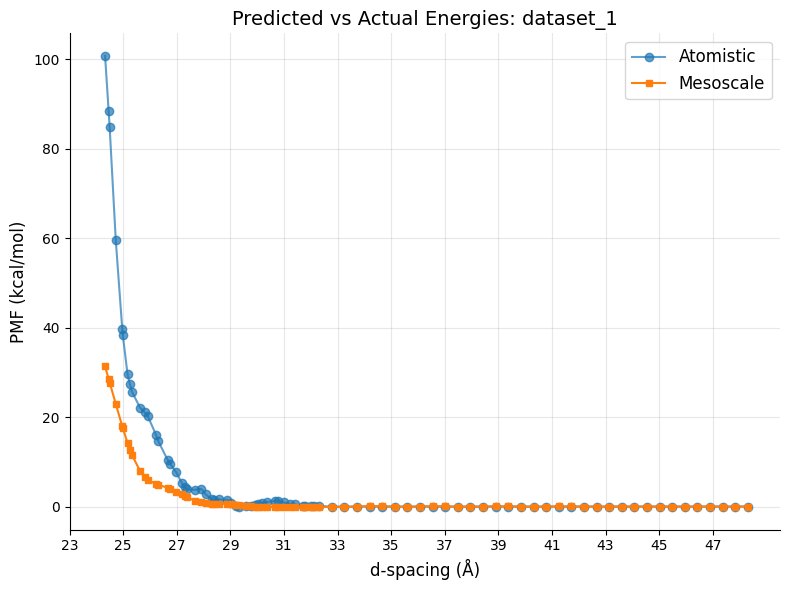

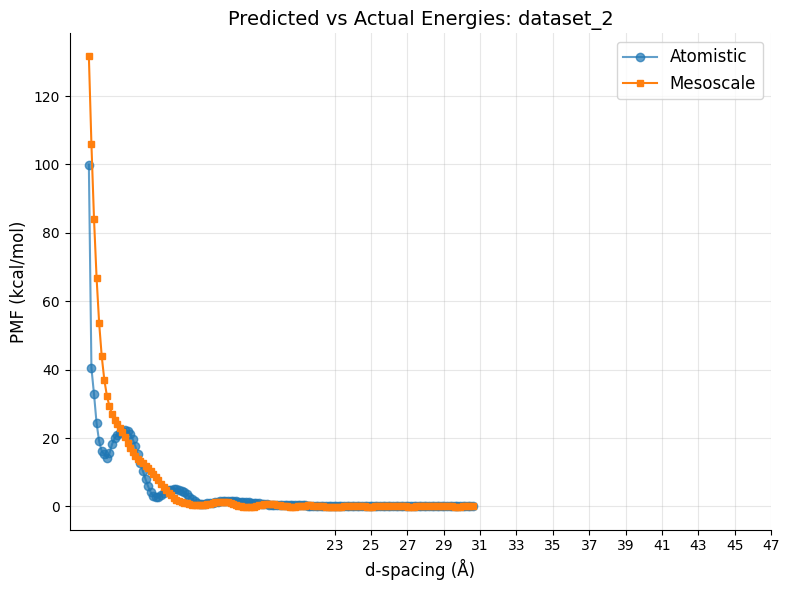

In [9]:
# Final EE Morse parameters used in the model

morse_ee = torch.tensor([-270.0342,    1.0854,   -1.2065], device=device)

def predict_energy(data):
    """Predict energy using optimized parameters."""
    predicted_energies = {}

    for dkey in data.keys():

        dist_ee = data[dkey]["edge_edge"]  
        
        actual = data[dkey]["actual"]  

        morse_cc_tensor =  precomputed[dkey]["morse_cc"]
        pred_cc_tensor = precomputed[dkey]["pred_cc"]
        morse_ec_tensor =  precomputed[dkey]["morse_ec"]
        pred_ec_tensor = precomputed[dkey]["pred_ec"]

        morse_ee_list = []
        

        for dist_tensor in dist_ee:
            morse_ee_energy = morse_potential(dist_tensor, *morse_ee).sum()
            morse_ee_list.append(morse_ee_energy)
            

            
            
            
        # Convert lists to tensors
        morse_ee_tensor = torch.stack(morse_ee_list)

        # Final predicted energy
        predicted =  morse_ee_tensor + morse_cc_tensor +  pred_cc_tensor + morse_ec_tensor + pred_ec_tensor
        predicted_energies[dkey] = predicted

    return predicted_energies

def plot_results(dkey, processed_data, predicted_energies, zoom=False):
    actual = processed_data[dkey]["actual"].cpu().numpy()
    predicted = predicted_energies[dkey].cpu().numpy()
    xvals = processed_data[dkey]["d_spacing_energy"].cpu().numpy()
    
    plt.figure(figsize=(8, 6))
    plt.plot(xvals, actual, 'o-', label="Atomistic", alpha=0.7)
    plt.plot(xvals, predicted, 's-', label="Mesoscale", markersize=5)
    
    plt.xlabel("d-spacing (Å)", fontsize=12)
    plt.ylabel("PMF (kcal/mol)", fontsize=12)
    plt.title(f"Predicted vs Actual Energies: {dkey}", fontsize=14)
    plt.legend(fontsize=12)
    
    if zoom:
        plt.ylim([-2, 5])
        plt.xlim([23, 48])
        plt.xticks(np.arange(23, 48, 1))
    else:
        plt.xticks(np.arange(23, 48, 2))
    
    ax = plt.gca()
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()

    

predicted_energies = predict_energy(processed_data)


 


# Print predicted energies
for dkey, predicted in predicted_energies.items():
    plot_results(dkey, processed_data, predicted_energies)
    print(f"{dkey} predicted energy: {predicted}")